# Mobile Regression 실습

## 데이터 불러오기

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

tf.keras.utils.set_random_seed(42)   # 결과 재현용 시드 고정

df = pd.read_csv('mobile.csv')
print(df.shape)                  # (2000, 21)

df = df.drop(columns='price_range')   # price_range 삭제: 가격대는 battery_power 등으로 정해진 값 → 입력에 넣으면 타깃 정보 누출
print(df.shape)                       # (2000, 20): 특성 19 + 타깃 1
df.head()

(2000, 21)
(2000, 20)


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi
0,842,0,2.2,0,1,0,7,0.6,188,2,2,20,756,2549,9,7,19,0,0,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,6,905,1988,2631,17,3,7,1,1,0
2,563,1,0.5,1,2,1,41,0.9,145,5,6,1263,1716,2603,11,2,9,1,1,0
3,615,1,2.5,0,0,0,10,0.8,131,6,9,1216,1786,2769,16,8,11,1,0,0
4,1821,1,1.2,0,13,1,44,0.6,141,2,14,1208,1212,1411,8,2,15,1,1,0


## 1. 결측치 확인

In [ ]:
display(df.isnull().sum().to_frame('NaN 개수').T)   # 컬럼별 NaN 개수 → 전부 0

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi
NaN 개수,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [ ]:
# NaN은 없지만 0이 들어갈 수 없는 컬럼에 0이 있으면 사실상 결측치
zero_cnt = (df == 0).sum()
display(zero_cnt[zero_cnt > 0].to_frame('0 개수').T)   # 이진 컬럼(blue, wifi 등)과 fc, pc의 0은 정상값(없음/미탑재)
display(df.describe().T)                               # min이 0인 컬럼 확인 → sc_w, px_height는 0이 나올 수 없음

,blue,dual_sim,fc,four_g,pc,px_height,sc_w,three_g,touch_screen,wifi
0 개수,1010,981,474,957,101,2,180,477,994,986


,count,mean,std,min,25%,50%,75%,max
battery_power,2000.0,1238.51850,439.418206,501.0,851.75,1226.0,1615.25,1998.0
blue,2000.0,0.49500,0.500100,0.0,0.00,0.0,1.00,1.0
clock_speed,2000.0,1.52225,0.816004,0.5,0.70,1.5,2.20,3.0
dual_sim,2000.0,0.50950,0.500035,0.0,0.00,1.0,1.00,1.0
fc,2000.0,4.30950,4.341444,0.0,1.00,3.0,7.00,19.0
four_g,2000.0,0.52150,0.499662,0.0,0.00,1.0,1.00,1.0
int_memory,2000.0,32.04650,18.145715,2.0,16.00,32.0,48.00,64.0
m_dep,2000.0,0.50175,0.288416,0.1,0.20,0.5,0.80,1.0
mobile_wt,2000.0,140.24900,35.399655,80.0,109.00,141.0,170.00,200.0
n_cores,2000.0,4.52050,2.287837,1.0,3.00,4.0,7.00,8.0


In [ ]:
# 화면 너비(sc_w)와 세로 해상도(px_height)가 0인 건 물리적으로 불가능 → 결측치로 판단
print('sc_w = 0      :', (df['sc_w'] == 0).sum(), '행')        # 180행
print('px_height = 0 :', (df['px_height'] == 0).sum(), '행')   # 2행

df[['sc_w', 'px_height']] = df[['sc_w', 'px_height']].replace(0, np.nan)   # 0 → NaN으로 표시
df.isnull().sum()[['sc_w', 'px_height']]   # 분할 후 train 중앙값으로 채움(4번 단계)

sc_w = 0      : 180 행
px_height = 0 : 2 행


,0
sc_w,180
px_height,2


## 2. 라벨 분포 확인

In [ ]:
# battery_power는 연속형 수치 → 값별 value_counts는 의미가 적음
print('고유값 개수:', df['battery_power'].nunique())   # 2000개 중 약 1100개가 서로 다른 값
df['battery_power'].describe()                          # 501 ~ 1998 mAh, 평균 약 1238

고유값 개수: 1094


,battery_power
count,2000.000000
mean,1238.518500
std,439.418206
min,501.000000
25%,851.750000
50%,1226.000000
75%,1615.250000
max,1998.000000


battery_power
(500, 875]      537
(875, 1250]     486
(1250, 1625]    490
(1625, 2000]    487
Name: count, dtype: int64


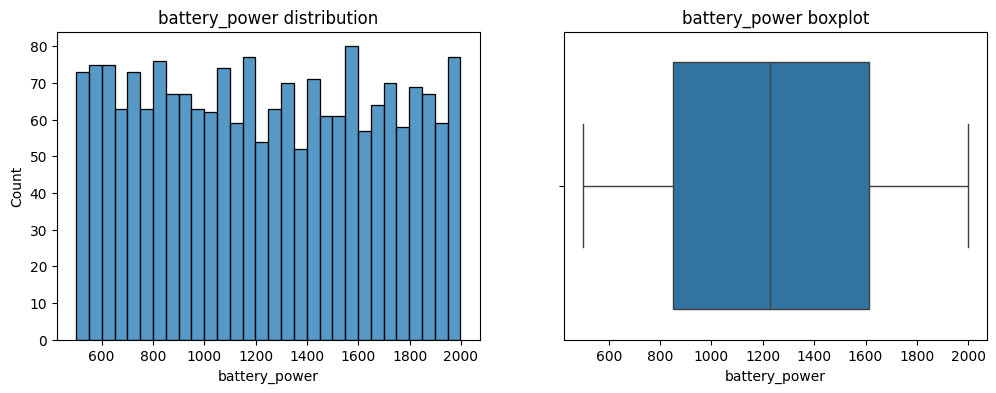

In [ ]:
# 구간으로 나눠서 개수 확인 → 특정 구간에 몰려 있는지(불균형) 점검
bins = pd.cut(df['battery_power'], bins=[500, 875, 1250, 1625, 2000])
print(bins.value_counts().sort_index())   # 각 구간 약 500개씩 고르게 분포

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['battery_power'], bins=30, ax=axes[0])   # 거의 균등분포 (한쪽으로 치우치지 않음)
axes[0].set_title('battery_power distribution')
sns.boxplot(x=df['battery_power'], ax=axes[1])           # 이상치 없음
axes[1].set_title('battery_power boxplot')
plt.show()

## 3. EDA

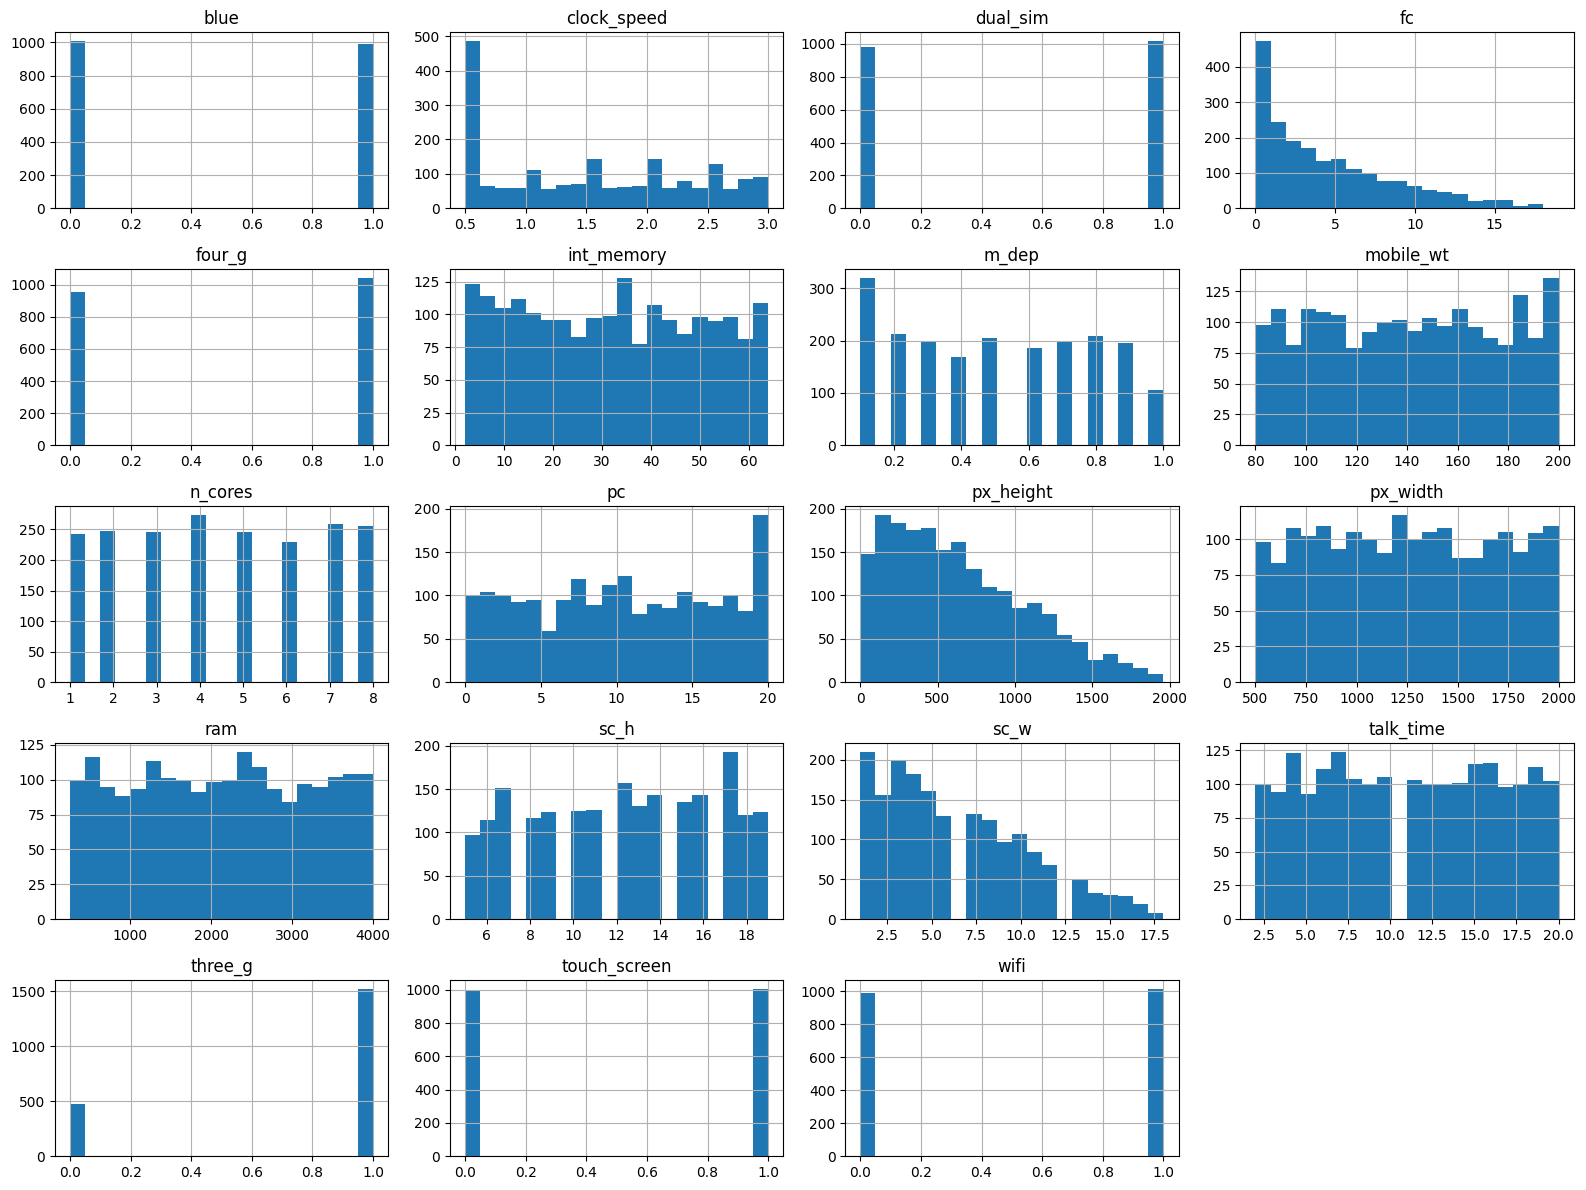

In [ ]:
df.drop(columns='battery_power').hist(figsize=(16, 12), bins=20)   # 입력 특성 분포
plt.tight_layout()                                                   # 대부분 균등분포, fc만 오른쪽 꼬리
plt.show()

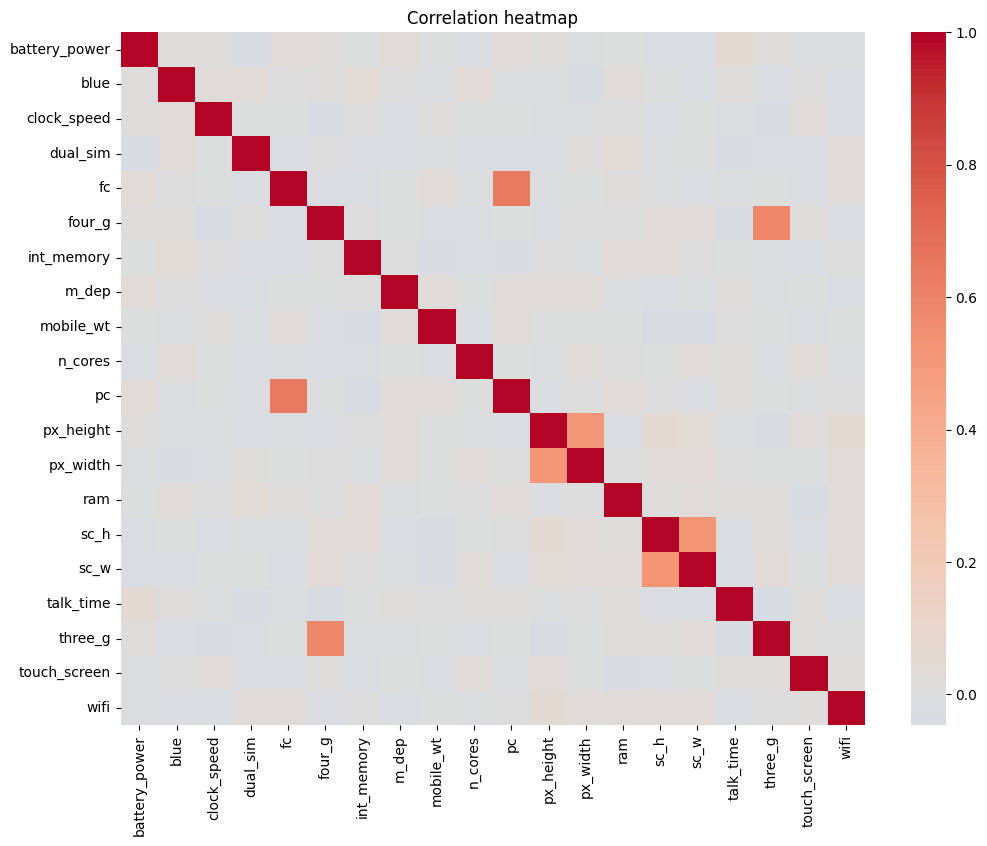

In [ ]:
plt.figure(figsize=(12, 9))
sns.heatmap(df.corr(), cmap='coolwarm', center=0)   # battery_power 행/열이 거의 흰색 → 어떤 특성과도 상관 없음
plt.title('Correlation heatmap')                    # 특성 간 최대 상관 fc-pc 0.64 → 강한 다중공선성 아님
plt.show()

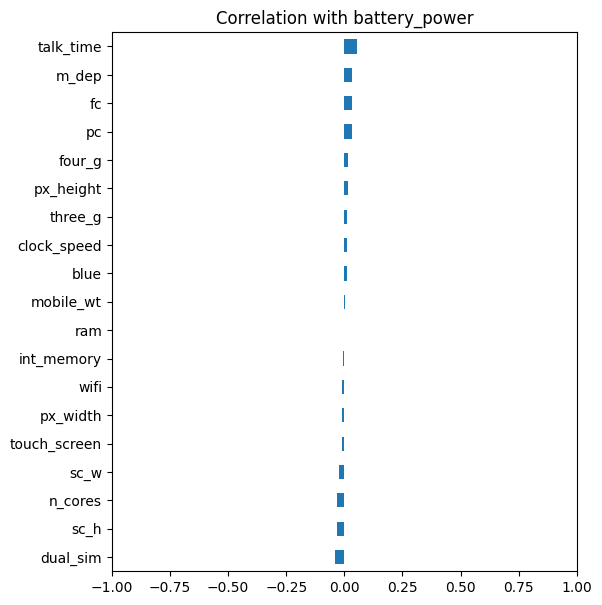

In [ ]:
corr = df.corr()['battery_power'].drop('battery_power').sort_values()   # 타깃과의 상관계수
corr.plot.barh(figsize=(6, 7))                                           # 최대 |0.05| 수준 → 예측 단서가 거의 없음
plt.title('Correlation with battery_power')
plt.xlim(-1, 1)                                                          # 축을 -1~1로 고정해 상관이 얼마나 약한지 표시
plt.show()

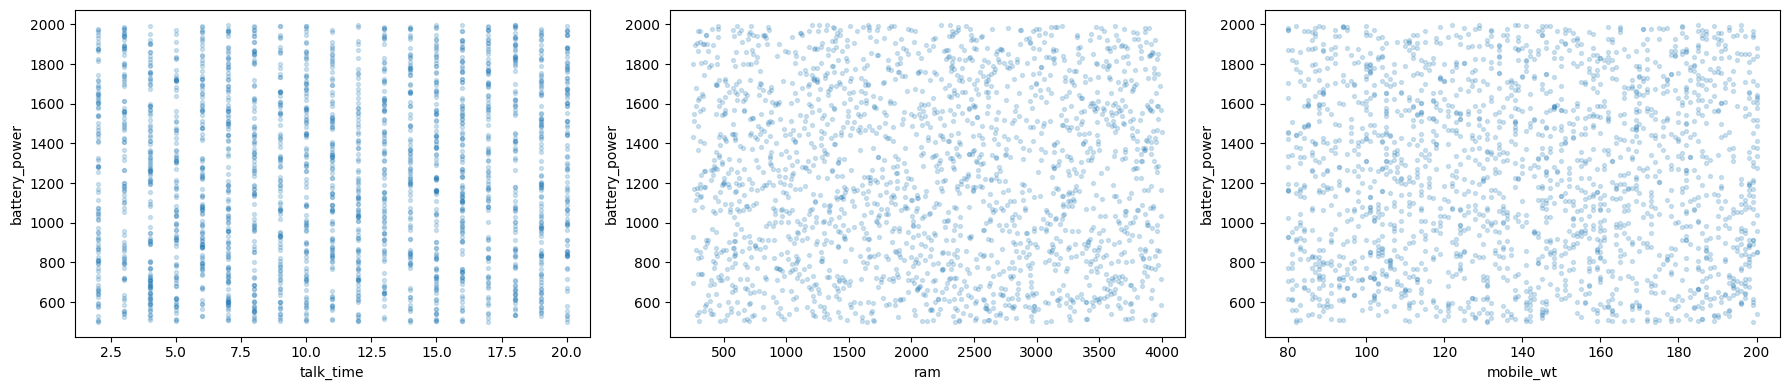

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, ['talk_time', 'ram', 'mobile_wt']):   # 상식적으로 배터리와 관련 있어 보이는 특성
    ax.scatter(df[col], df['battery_power'], alpha=0.2, s=8)    # 점이 고르게 흩어짐 → 관계 없음
    ax.set_xlabel(col); ax.set_ylabel('battery_power')
plt.tight_layout()
plt.show()

## 4. 데이터 분할 · 결측치 처리 · 스케일링

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns='battery_power')   # 입력: 사양 19개
y = df['battery_power']                # 타깃: 배터리 용량(mAh)

# train 60% / validation 20% / test 20%
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)                    # test는 마지막 최종 평가에만 사용
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42)         # 모델 비교·원인 분석은 validation으로

medians = X_train[['sc_w', 'px_height']].median()   # train 기준 중앙값 (val/test 정보 누출 방지)
X_train, X_val, X_test = X_train.fillna(medians), X_val.fillna(medians), X_test.fillna(medians)
print('남은 결측치:', X_train.isnull().sum().sum(), X_val.isnull().sum().sum(), X_test.isnull().sum().sum())

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # train으로만 평균/표준편차 학습
X_val_s   = scaler.transform(X_val)         # val/test는 변환만
X_test_s  = scaler.transform(X_test)

print(X_train.shape, X_val.shape, X_test.shape)   # (1200, 19) (400, 19) (400, 19)

남은 결측치: 0 0 0
(1200, 19) (400, 19) (400, 19)


In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

def reg_score(y_true, y_pred):
    return {'R2':   r2_score(y_true, y_pred),                    # 1이면 완벽, 0이면 평균 찍기와 같음, 음수면 그보다 못함
            'MAE':  mean_absolute_error(y_true, y_pred),         # 평균 절대 오차 (mAh 단위)
            'RMSE': mean_squared_error(y_true, y_pred) ** 0.5}   # 큰 오차에 더 민감

# 기준선: 입력을 무시하고 train 평균으로만 예측 → 모든 모델은 이것보다 나아야 의미 있음
baseline_pred = np.full(len(y_val), y_train.mean())
print('기준선(평균) val:', {k: round(v, 3) for k, v in reg_score(y_val, baseline_pred).items()})

기준선(평균) val: {'R2': -0.0, 'MAE': 388.236, 'RMSE': 447.154}


## 5. 딥러닝(DNN) 모델

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

def build_model(hidden=(64, 32), last_activation='linear'):
    model = keras.Sequential([layers.Input(shape=(19,))])          # 입력: 특성 19개
    for units in hidden:
        model.add(layers.Dense(units, activation='relu'))          # 은닉층
    model.add(layers.Dense(1, activation=last_activation))         # 출력층: 노드 1개, linear → 범위 제한 없는 실수값 출력
    model.compile(
        optimizer='adam',
        loss='mse',          # 회귀 loss: 평균제곱오차 (큰 오차에 큰 벌점)
        metrics=['mae'],     # 해석하기 쉬운 평균 절대 오차(mAh)로 모니터링
    )
    return model

def train_eval(model, Xtr, Xv, epochs=1000):
    early_stop = keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=20,    # val loss가 20 epoch 동안 안 줄면 중단
        restore_best_weights=True)          # 가장 좋았던 시점의 가중치로 복원 → 과적합 방지
    hist = model.fit(Xtr, y_train, validation_data=(Xv, y_val),
                     epochs=epochs, batch_size=32, callbacks=[early_stop], verbose=0)
    pred = model.predict(Xv, verbose=0).ravel()   # (n, 1) → (n,)
    return hist, reg_score(y_val, pred)

dnn = build_model()
dnn.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 64)             │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history, dnn_score = train_eval(dnn, X_train_s, X_val_s)
print('학습 epoch 수:', len(history.history['loss']))
print('DNN val:', {k: round(v, 3) for k, v in dnn_score.items()})   # R2가 0 근처 → 기준선과 차이 없음

학습 epoch 수: 127
DNN val: {'R2': -0.067, 'MAE': 394.018, 'RMSE': 461.901}


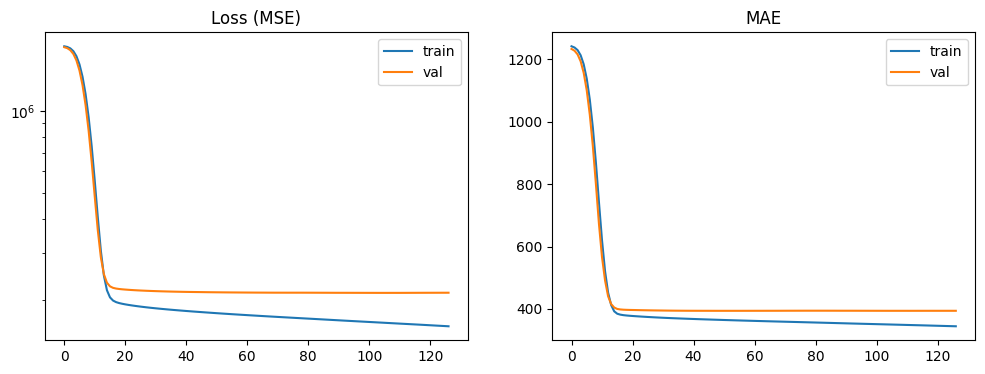

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history['loss'], label='train')
axes[0].plot(history.history['val_loss'], label='val')   # 초반: 평균값을 찾아가며 급감 / 이후: val loss 정체
axes[0].set_title('Loss (MSE)'); axes[0].set_yscale('log'); axes[0].legend()
axes[1].plot(history.history['mae'], label='train')
axes[1].plot(history.history['val_mae'], label='val')    # val MAE가 기준선(약 388) 근처에서 멈춤
axes[1].set_title('MAE'); axes[1].legend()
plt.show()

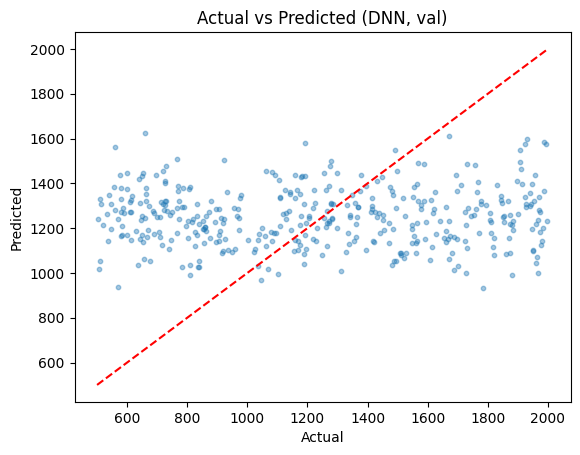

In [ ]:
dnn_pred = dnn.predict(X_val_s, verbose=0).ravel()
plt.scatter(y_val, dnn_pred, alpha=0.4, s=10)
plt.plot([500, 2000], [500, 2000], 'r--')      # 빨간 선 = 완벽한 예측
plt.xlabel('Actual'); plt.ylabel('Predicted')   # 예측값이 평균(약 1240) 근처 가로띠에 몰림 → 입력과 무관하게 비슷한 값 출력
plt.title('Actual vs Predicted (DNN, val)')
plt.show()

## 6. 머신러닝 모델과 비교 (validation)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor

models = {
    'Linear Regression': LinearRegression(),                        # 선형 기준 모델
    'KNN':               KNeighborsRegressor(),                     # 거리 기반
    'Random Forest':     RandomForestRegressor(random_state=42),    # 비선형 앙상블 → 과적합 분석에 사용
}

results = [{'model': 'Baseline (평균)', **reg_score(y_val, baseline_pred)},
           {'model': 'DNN (은닉층 2개)', **dnn_score}]
for name, m in models.items():
    m.fit(X_train_s, y_train)
    results.append({'model': name, **reg_score(y_val, m.predict(X_val_s))})

result_df = pd.DataFrame(results).sort_values('R2', ascending=False).round(3)
result_df   # 모든 모델이 기준선(R2 0)과 비슷하거나 더 나쁨

,model,R2,MAE,RMSE
0,Baseline (평균),-0.000,388.236,447.154
2,Linear Regression,-0.012,388.828,449.803
4,Random Forest,-0.067,398.976,461.788
1,DNN (은닉층 2개),-0.067,394.018,461.901
3,KNN,-0.184,415.168,486.508


## 7. 성능이 낮은 원인 분석 (validation)

In [ ]:
# [원인 1] 입력 특성에 battery_power를 설명할 정보가 없음
print('타깃과 상관이 가장 큰 특성 |r|:', round(corr.abs().max(), 3))   # 0.05 수준 → 사실상 무관
print('기준선 MAE      :', round(reg_score(y_val, baseline_pred)['MAE'], 1))
print('Linear Reg. MAE :', round(result_df.set_index('model').loc['Linear Regression', 'MAE'], 1))   # 평균 찍기와 거의 같음

타깃과 상관이 가장 큰 특성 |r|: 0.053
기준선 MAE      : 388.2
Linear Reg. MAE : 388.8


In [ ]:
# [원인 2] price_range 삭제로 유일한 단서가 사라짐 (원인 확인용 실험, 최종 모델에는 사용 안 함)
price = pd.read_csv('mobile.csv')['price_range']   # 삭제했던 price_range 다시 불러오기
Xtr_p = np.column_stack([X_train_s, price.loc[X_train.index]])
Xv_p  = np.column_stack([X_val_s,   price.loc[X_val.index]])

lr_p = LinearRegression().fit(Xtr_p, y_train)
print('price_range 없음 R2:', round(result_df.set_index('model').loc['Linear Regression', 'R2'], 3))   # 약 0
print('price_range 포함 R2:', round(r2_score(y_val, lr_p.predict(Xv_p)), 3))   # 상승 → 배터리 정보는 price_range에만 있었음

price_range 없음 R2: -0.012
price_range 포함 R2: 0.261


RF train R2: 0.856
RF val   R2: -0.067


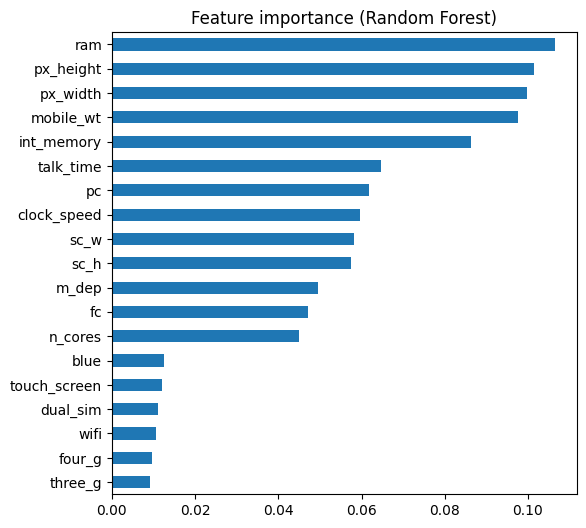

In [ ]:
# [원인 3] 복잡한 모델은 의미 없는 노이즈까지 외움 (과적합)
rf = models['Random Forest']
print('RF train R2:', round(r2_score(y_train, rf.predict(X_train_s)), 3))   # 높음 → train은 외움
print('RF val   R2:', round(r2_score(y_val,   rf.predict(X_val_s)), 3))     # 음수 → 새 데이터엔 통하지 않음

rf_imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
rf_imp.plot.barh(figsize=(6, 6))   # 중요도가 고르게 퍼짐 → 특별히 쓸모 있는 특성이 없다는 뜻
plt.title('Feature importance (Random Forest)')
plt.show()

In [ ]:
# [원인 4] 출력층 activation: linear의 필요성을 확인하기 위한 대조 실험
# sigmoid는 출력이 0~1로 제한 → 500~2000 범위의 배터리 값을 낼 수 없음
tf.keras.utils.set_random_seed(42)
_, sig_score = train_eval(build_model(last_activation='sigmoid'), X_train_s, X_val_s)
print('출력층 sigmoid R2:', round(sig_score['R2'], 3), '/ MAE:', round(sig_score['MAE'], 1))   # 크게 음수, MAE 1000 이상
print('출력층 linear  R2:', round(dnn_score['R2'], 3), '/ MAE:', round(dnn_score['MAE'], 1))

출력층 sigmoid R2: -7.625 / MAE: 1234.6
출력층 linear  R2: -0.067 / MAE: 394.0


## 8. 최종 평가 (test)

In [ ]:
# validation 기준 기준선을 의미 있게 넘은 모델이 없음 → 가장 단순한 Linear Regression을 최종 모델로 선택
final_model = models['Linear Regression']
test_pred = final_model.predict(X_test_s)
test_base = np.full(len(y_test), y_train.mean())

print('최종 모델 test:', {k: round(v, 3) for k, v in reg_score(y_test, test_pred).items()})
print('기준선    test:', {k: round(v, 3) for k, v in reg_score(y_test, test_base).items()})   # 거의 같음

최종 모델 test: {'R2': -0.024, 'MAE': 383.881, 'RMSE': 439.247}
기준선    test: {'R2': -0.001, 'MAE': 378.687, 'RMSE': 434.225}


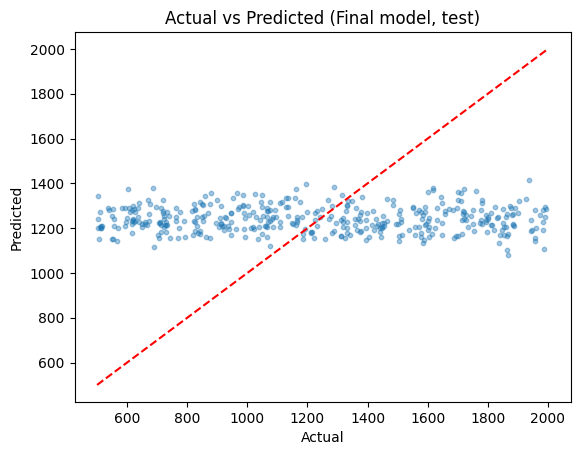

In [ ]:
plt.scatter(y_test, test_pred, alpha=0.4, s=10)
plt.plot([500, 2000], [500, 2000], 'r--')      # 빨간 선 = 완벽한 예측
plt.xlabel('Actual'); plt.ylabel('Predicted')   # 예측이 평균 근처에 몰림 → 이 특성들로는 배터리 용량 예측 불가
plt.title('Actual vs Predicted (Final model, test)')
plt.show()

## 9. 결과 정리

**평가 방식**
- 데이터를 train 60% / validation 20% / test 20%로 나눴다.
- 모델 비교와 원인 분석은 모두 validation으로 했고, test는 최종 모델 평가에 **한 번만** 사용했다.
- 입력을 무시하고 train 평균만 예측하는 **기준선(Baseline)** 을 두고, 모델이 이보다 나은지를 기준으로 판단했다.

**모델별 Validation 결과**

| 모델 | R² | MAE (mAh) |
|---|---|---|
| Baseline (평균 예측) | 0.000 | 388.2 |
| Linear Regression | -0.012 | 388.8 |
| DNN (은닉층 2개) | -0.067 | 394.0 |
| Random Forest | -0.067 | 399.0 |
| KNN | -0.184 | 415.2 |

- 모든 모델이 평균값만 찍는 기준선과 비슷하거나 더 나빴다. 즉, **입력 특성으로 battery_power를 예측하지 못했다.**

**5. 성능이 낮은 원인 분석 (validation 기준)**

| 원인 | 실험 | 결과 |
|---|---|---|
| ① 입력에 예측 단서가 없음 | 타깃과의 최대 상관, 기준선과 MAE 비교 | \|r\| 0.05, MAE 388.2 vs 388.8 |
| ② price_range 삭제로 유일한 단서 소실 | price_range 다시 추가 (확인용) | R² -0.012 → **0.261** |
| ③ 복잡한 모델의 과적합 | Random Forest train vs val | R² 0.856 → **-0.067** |
| ④ 출력층 activation (대조 실험) | 출력층 sigmoid vs linear | MAE 1234.6 vs 394.0 |

- ① 가장 근본적인 원인이다. 데이터에 battery_power와 관계있는 특성이 없으니, 어떤 모델을 써도 학습할 패턴이 없다. 모델 문제가 아니라 **데이터(특성)의 한계**다.
- ② battery_power의 정보는 price_range에만 담겨 있었다. 다시 넣으면 R²가 0.26으로 오르지만, 이는 타깃 누출이므로 원인 확인용으로만 쓰고 최종 모델에는 사용하지 않았다.
- ③ Random Forest는 train에서 R² 0.86으로 잘 맞췄지만 val에서는 음수였다. 의미 없는 노이즈를 외운 것이고, 그래서 복잡한 모델(RF, DNN, KNN)일수록 기준선보다 더 나빠졌다. 특성 중요도도 고르게 퍼져 특별히 쓸모 있는 특성이 없음을 보여줬다.
- ④ 출력층에 sigmoid를 쓰면 출력이 0 ~ 1로 제한되어 500 ~ 2000 범위의 값을 낼 수 없다. MAE가 평균값(약 1238) 수준으로 커져, 회귀 출력층에는 linear가 필요함을 확인했다.

**최종 결과 (test)**
- validation에서 기준선을 의미 있게 넘은 모델이 없어, 가장 단순한 Linear Regression을 최종 모델로 선택했다.
- test R² -0.024, MAE 383.9로 기준선(R² -0.001, MAE 378.7)과 거의 같았다.
- 결론: **price_range를 제외한 휴대폰 사양만으로는 battery_power를 예측할 수 없다.**

**느낀 점**
- 성능이 낮을 때 모델을 바꾸거나 복잡하게 만드는 것보다, 먼저 EDA로 입력과 타깃 사이에 관계가 있는지 확인하는 것이 중요하다는 것을 배웠다.
- R²나 MAE 숫자만 보지 않고 "평균만 찍는 기준선"과 비교해야 모델이 실제로 무언가를 배웠는지 판단할 수 있었다.
- 복잡한 모델일수록 학습 데이터는 잘 맞추지만, 학습할 패턴이 없을 때는 노이즈를 외워 오히려 더 나빠진다는 점을 확인했다.
- price_range처럼 타깃에서 파생된 특성을 넣으면 점수는 오르지만 그건 진짜 예측이 아니라는 점, 즉 타깃 누출을 주의해야 한다는 것을 알게 되었다.